# Real Cordoba elastic lidar: return profiles to aerosol fields


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：cordoba_lidar_aerosol_mapping

**观测 y：** range_corrected_signal(1, 66, 4096)；molecular_backscatter(1, 4096)；molecular_extinction(1, 4096)；range(1, 4096)；time_start(1, 66)；time_stop(1, 66)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 气溶胶后向散射与消光时高场。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 弹性激光雷达:回波=(分子+气溶胶散射)exp(-2∫消光)。本地路径为 `solvers.reconstruct→fernald`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 7（cell编号按文件内从0计）。章节包括：# Real Cordoba elastic lidar: return profiles to aerosol fields；## 1. Problem；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 固定激光雷达比/参考高度条件，无独立大气真值。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Recover aerosol backscatter and extinction over the complete selected time-height field from real elastic-lidar returns. A fixed aerosol lidar ratio couples these two outputs, so they are not independently measured quantities.

All66complete averaged532nm observation profiles are real LidarPi measurements from2024-10-02. They come from the original399native LICEL files, processed by actual L0/L1/L2C++programs. The source's six-record averaging retains396records and discards the incomplete last3. This selected benchmark recovers the complete calibrated time-height field below the reference layer,66times759heights. The full corrected return and known molecular prior are public.

The elastic equation is S=G*(beta_m+beta_a)*exp[-2 integral(alpha_m+alpha_a)dr]. Fix alpha_a=L*beta_a with L50sr and impose aerosol-free backscatter at the reference height. These assumptions resolve a conditional inverse; they do not independently measure lidar ratio or true aerosol concentration. After reference normalization, an integrating factor p=(S/Sref)*exp[-2*(L/L_m-1)*integral_ref(alpha_m)dr] gives beta_total=p/[1/beta_m(ref)-2L*integral_ref(p)dr]. Subtract the known molecular beta and multiply by L for aerosol extinction.

The known molecular profile comes from the author's standard atmosphere, not an in situ radiosonde. Unverified interchannel gluing/polarization calibration is disabled; a single real analog channel is used. Full overlap above the excluded lower range, trigger/background correction, and the clear-air reference remain explicit assumptions. Negative weak-aerosol estimates are preserved and shown, not clipped or presented as true negative scattering.


## 2. Data

The author LidarPi acquisition contains 66 complete six-record averages at 532 nm and 759 evaluated heights. One real analog channel is used; full corrected returns and a standard-atmosphere molecular prior are public. The incomplete final three records were discarded upstream.

`data/raw_data.npz` contains these batch-first observation/calibration arrays:

| Key | Shape | Dtype | Description |
|---|---|---|---|
| range_corrected_signal | (1, 66, 4096) | float64 | Corrected mean analog return times range², ADC count m²; axes batch,time,range |
| molecular_backscatter | (1, 4096) | float64 | Known standard-atmosphere molecular backscatter, m^-1 sr^-1 |
| molecular_extinction | (1, 4096) | float64 | Known standard-atmosphere molecular extinction, m^-1 |
| range | (1, 4096) | float64 | Recorded slant-range bin centers above lidar, m |
| time_start | (1, 66) | int32 | Start of each integration, Unix seconds UTC |
| time_stop | (1, 66) | int32 | End of each integration, Unix seconds UTC |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Real observation | LidarPi,2024-10-02 | UTC date | Author-provided native LICEL records, Cordoba region |
| Site coordinates | latitude-31.2,longitude-64.1,altitude411 | degree north/east;m ASL | Instrument-header location |
| Wavelength / source channel | 532 /6 | nm /zero-based index | Analog elastic channel; no analog/photon gluing or polarization mixing |
| Pointing | zenith0 | degree | Vertical slant range equals height above instrument |
| Range sampling | 7.5 | m | Centers (index+0.5)*7.5,4096bins |
| Evaluated range indices | 54to812inclusive | zero-based index | 759bins,408.75to6093.75m above instrument |
| Native/time averaging | 399native records; six-record analog means;66complete groups | records | Original averaging rule discards final incomplete three-record group |
| Laser repetition / native accumulation | 10 /101 | Hz /pulses | Header instrument information; individual native records are approximately10s |
| Trigger correction | channel6offset5 | bins | Author configuration; known preprocessing assumption |
| Instrument background | mean over25000to30000 | m | Source-supported sky/electronic background correction before range correction |
| Dark/overlap correction | none supplied; unity overlap assumed in evaluated range | - | No invented dark/overlap calibration; lower heights excluded |
| Molecular atmosphere | source-provided US Standard Atmosphere thermodynamic profile and Rayleigh calculation | - | Known prior, not an in situ radiosonde or target-derived atmosphere |
| Molecular lidar ratio | 8.496628478899588 | sr | alpha_m/beta_m in the supplied valid molecular profile |
| Aerosol lidar ratio L | 50 | sr | Fixed conditional extinction/backscatter prior |
| Reference interval | source configured6000to7000ASL,indices745to879 | m /indices | Fit calibrated return to known molecular return plus constant over this interval |
| Reference bin | 812 | zero-based index | Middle of configured reference interval; fitted reference return already replaces this signal sample |
| Reference location convention | recorded center6093.75AGL; source index-based print6090AGL/6501ASL | m | Half-bin distinction is explicit; use supplied range centers for field coordinates |
| Boundary backscatter ratio | 1 | dimensionless | Total/molecular backscatter at reference; aerosol-free assumption |
| Input signal scale | mean analog ADC counts times range² | count m² | Absolute analog gain cancels under reference normalization; not photon counts or millivolts |

The molecular arrays are the actual known L2 prior evaluated by the source, including its resampling conventions. They are not estimated from a hidden aerosol reconstruction. The full calibrated return is public so the reference layer and complete geometry are available. Gaussian/Poisson noise variances are not independently supplied; the forward criterion therefore uses a clearly defined relative return RMS rather than an invented photon-noise model. No co-located aerosol truth or AERONET constraint is assumed.


## 3. Physics

Elastic return combines molecular plus aerosol backscatter and two-way extinction. Reference normalization removes unknown analog gain, while the clear-air boundary and fixed 50 sr aerosol ratio make the Fernald inverse conditional on acquisition assumptions.

Use all 66 calibrated 532nm profiles from the real 2024-10-02 LidarPi observation in the Cordoba region. Recover 759 height bins for each profile, corresponding exactly to public range indices54through812inclusive. The supplied range-corrected signal is S(r,t)=r²P(r,t), with instrument background/trigger correction and time averaging already performed. Its physical model is


$$
S(r,t)=G(t)[\beta_m(r)+\beta_a(r,t)]
\exp\left[-2\int_0^r[\alpha_m(s)+\alpha_a(s,t)]\,ds\right],
\qquad \alpha_a=L\beta_a.
$$


Here r is slant range in m, t indexes integration windows, G is an unknown multiplicative instrument factor, beta and alpha are backscatter and extinction, subscripts m and a mean molecular and aerosol, and L is the prescribed aerosol lidar ratio in sr. Known molecular profiles are supplied. Normalize the return at reference bin812 to remove G, and impose aerosol-free total backscatter beta_total(reference)=beta_m(reference). Retrieval is conditional on these priors, not independent identification of L or temperature.


## 4. Method

The local inverse retains source quadrature and the exact sequential in-place 11-bin smoothing. Fresh 30 and 70 sr inversions isolate ratio sensitivity; a symmetric convolution would change the selected numerical method.

The Fernald family separates known molecular scattering from the unknown aerosol contribution. A reference-centered integrating factor converts the nonlinear elastic-lidar relation into a direct integral expression for total backscatter. Subtract the known molecular backscatter and use the fixed lidar ratio for extinction. Short vertical smoothing reduces noise amplification; its exact numerical convention affects the standard retrieval and should be kept explicit.


## 5. Results

All six retained groups compare measured returns, original C++ results, fresh backscatter/extinction, nonlinear forward residuals, ratio sensitivity and smoothing behavior. Extinction integrated only over evaluated heights is a partial-range optical depth, not total-column AOD.

### Actual field comparisons and conditional sensitivity

The original C++run is an independent method result, not atmospheric truth. The selected Fernald inverse and its exact source in-place11bin smoothing are both explicitly local. Earlier updated samples enter later moving averages; replacing this with a symmetric convolution would change the reference method.

We compute additional full-field inversions at lidar ratios30and70sr, compare original and fresh fields, and forward-project both smoothed physical fields against every real normalized return. The six groups display acquisition, both aerosol quantities, numerical parity, forward residuals, prior sensitivity, smoothing and weak-signal behavior. The extinction integral is restricted to the measured/evaluated heights and is not labeled total-column AOD. No missing AERONET or independently measured aerosol truth is inserted.

### Independent evaluation

The standalone evaluator imports no source modules. It computes reference agreement for all samples of both beta and alpha, then independently integrates optical depth using a cumulative forward sum. It predicts normalized elastic returns once from submitted beta and once from alpha/50. Every physical-output metric must pass. A relative return RMS is used because independent photon/count noise variances are not provided; source smoothing and noise explain its nonzero baseline value. Positive total backscatter is required even when a weak aerosol difference is negative.

Independent tests also check analytical molecular-only Beer-Lambert behavior, gain invariance, constant/linear quadrature and exact source alias smoothing. These checks provide evidence beyond agreement with two copies of an equation.

The complete fresh fields pass both independent source agreement and nonlinear return checks. The actual lidar-ratio and smoothing comparisons show why these conditional fields must not be interpreted as unique aerosol truth. No additional independent extinction degree of freedom is claimed under the fixed ratio.


In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print('Executed interpreter:',sys.executable,sys.version)
print('NumPy:',np.__version__)
root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import make_figures
started=time.perf_counter();data=load_data();output,stages=reconstruct(data)
seconds=time.perf_counter()-started
(root/'output').mkdir(exist_ok=True);np.savez_compressed(root/'output/reconstruction.npz',**output)
print('Fresh complete reconstruction seconds:',seconds)
print('Both field shapes:',{k:v.shape for k,v in output.items()})
print('Negative weak-aerosol estimate fraction:',np.mean(output['reconstruction']<0))


Executed interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe 3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]
NumPy: 2.4.6
Fresh complete reconstruction seconds: 0.07180650000373134
Both field shapes: {'reconstruction': (1, 66, 759), 'extinction': (1, 66, 759)}
Negative weak-aerosol estimate fraction: 0.23326146843933404


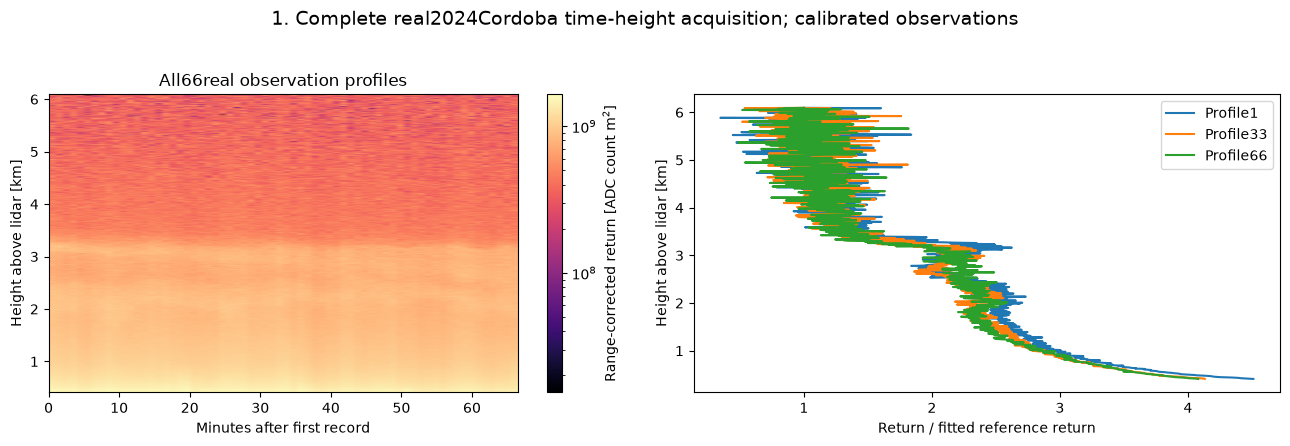

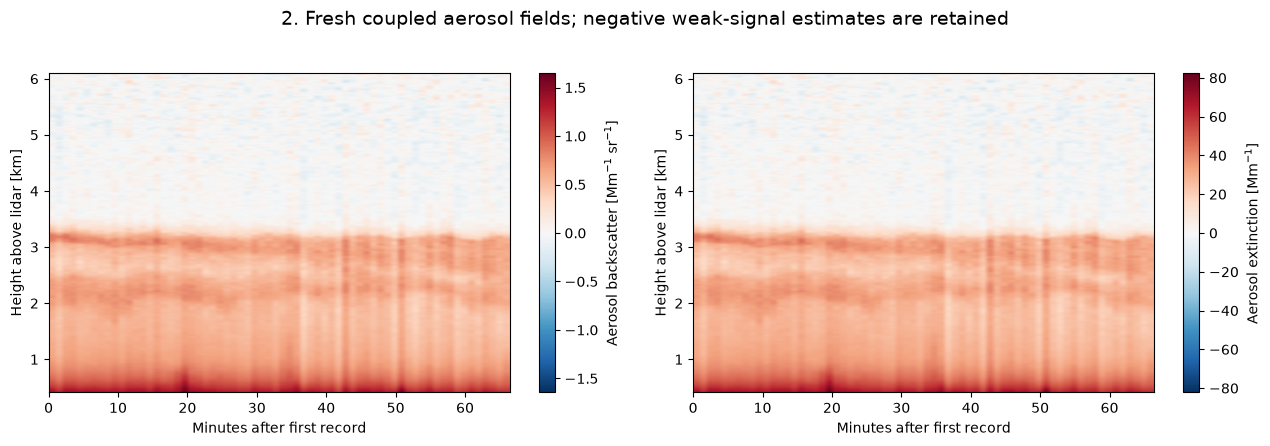

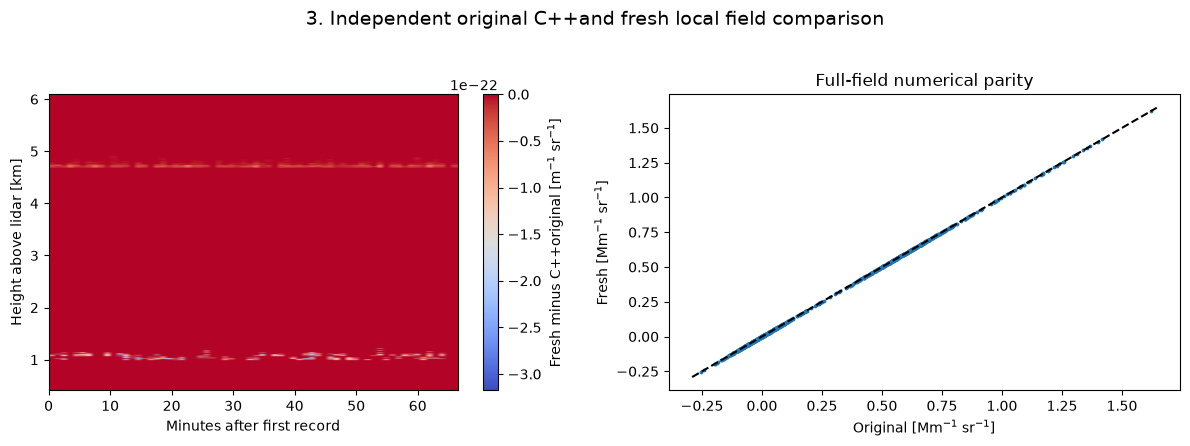

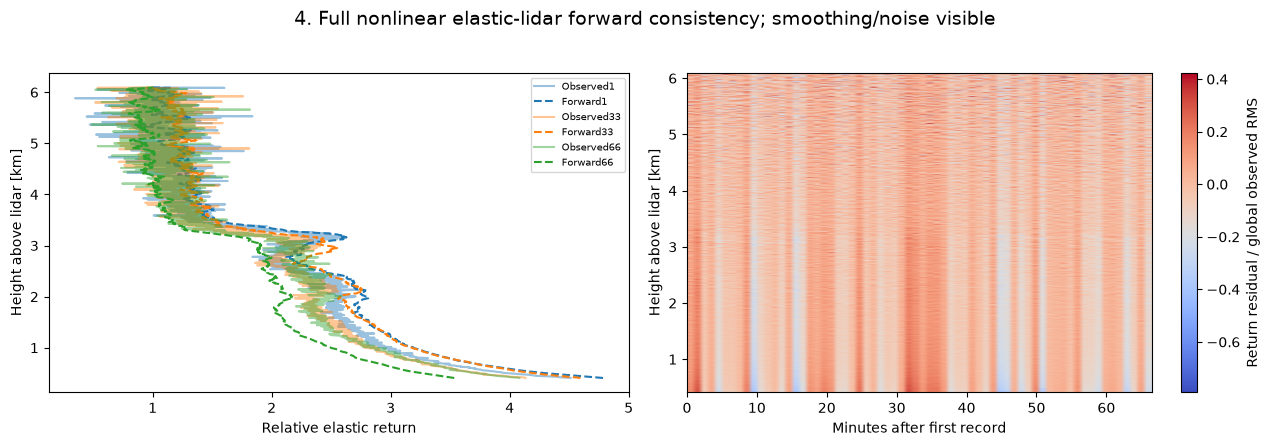

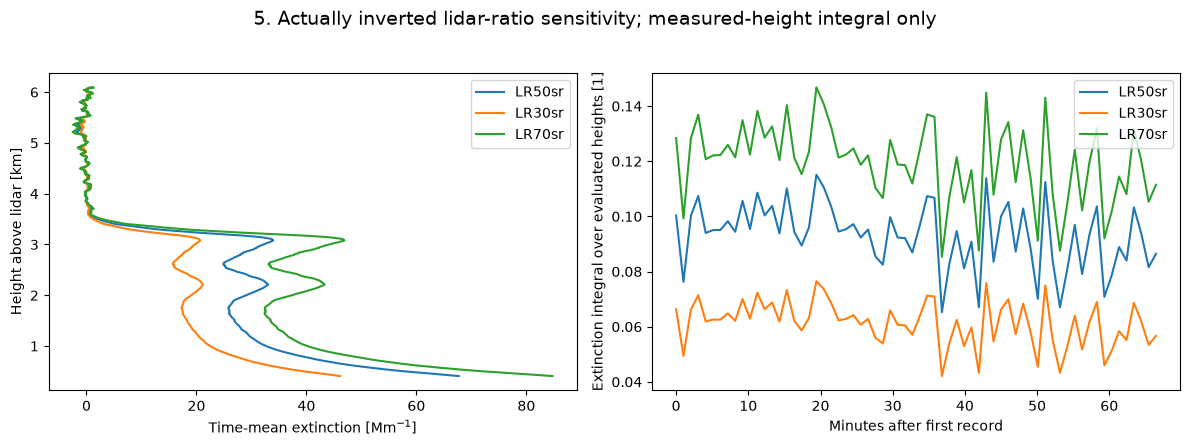

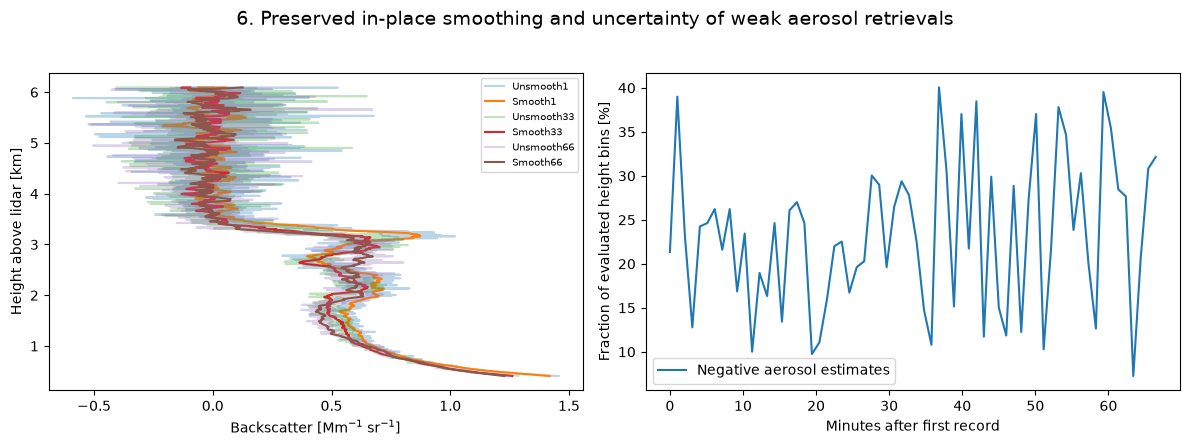

In [2]:
experiments={50:output}
for lr in [30,70]:experiments[lr]=reconstruct(data,lidar_ratio=lr)[0]
with np.load(root/'notebooks/reference_outputs/upstream_original.npz',allow_pickle=False) as z:source={k:z[k] for k in z.files}
export=Path('D:/yan1/agent/AutoSkill/imaging-101-maintainer/research_batch5_20261021/astro_earth/figures/cordoba_lidar_aerosol_mapping')
figures=make_figures(data,output,stages,source,experiments,export)
for fig in figures:
    display(fig)
    plt.close(fig)


In [3]:
import subprocess
result=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
report=json.loads((root/'output/judge_report.json').read_text(encoding='utf8'))
print(json.dumps(report,indent=2));assert result.returncode==0,result.stderr
(export/'metrics.json').write_text(json.dumps({'fresh':report,'fresh_seconds':seconds,'negative_aerosol_fraction':float(np.mean(output['reconstruction']<0))},indent=2),encoding='utf8')


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "backscatter_ncc": 1.0,
    "backscatter_nrmse": 5.4402279319423535e-18,
    "extinction_ncc": 1.0000000000000002,
    "extinction_nrmse": 5.363534215099801e-18,
    "backscatter_return_rms": 0.10870309474048033,
    "extinction_return_rms": 0.10870309474048034
  },
  "thresholds": {
    "backscatter_ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "backscatter_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "extinction_ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "extinction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "backscatter_return_rms": {
      "comparison": "<=",
      "boundary": 0.11957340421452838
    },
    "extinction_return_rms": {
      "comparison": "<=",
      "boundary": 0.11957340421452838
    }
  },
  "errors": []
}


1092

## 6. Conclusion

Source agreement and independent return checks support this conditional single-channel extraction. The unmeasured lidar ratio, assumed overlap and standard atmosphere limit physical interpretation; no AERONET truth or independent extinction information is claimed.
